  Preparing metadata (setup.py) ... done
  Created wheel for minisom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=9ee03a663e56ce40bb59c1bba8d70619239decc916882b693192b478ecf16bc0
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built minisom
dataset shape: (150, 4)

som training completed


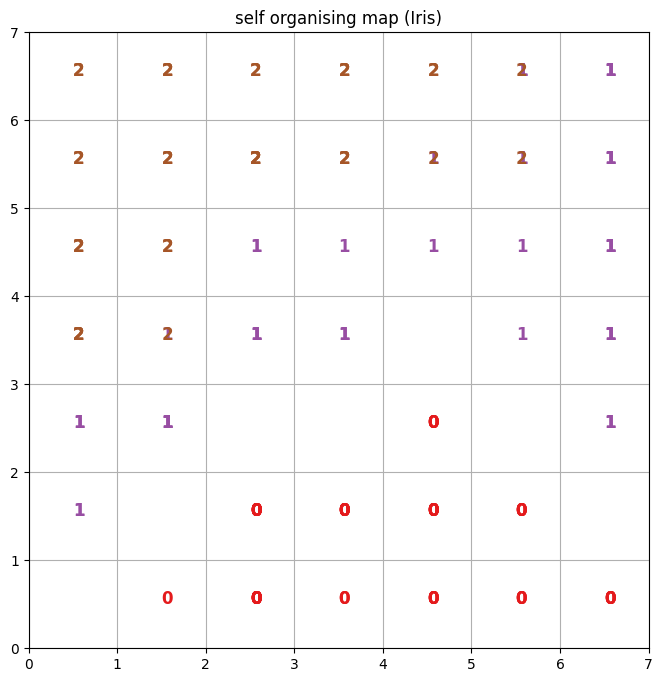

In [ ]:
!pip install minisom pandas scikit-learn matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom
iris=load_iris(as_frame=True)
x=iris.data.values
y=iris.target
print("dataset shape:",x.shape)
scaler=MinMaxScaler()
x_scaled=scaler.fit_transform(x)
som_size=7
som=MiniSom(x=som_size,y=som_size,input_len=x_scaled.shape[1],sigma=1.0,learning_rate=0.5,random_seed=42)
som.random_weights_init(x_scaled)
som.train_random(x_scaled,num_iteration=1000)
print('\nsom training completed')
plt.figure(figsize=(8,8))
for i,x in enumerate(x_scaled):
    w=som.winner(x)
    plt.text(w[0]+0.5,w[1]+0.5,str(y[i]),color=plt.cm.Set1(y[i]/3.),fontdict={'weight':'bold','size':12})
plt.title('self organising map (Iris)')
plt.xlim([0,som_size])
plt.ylim([0,som_size])
plt.grid(True)
plt.show()
